# 01 · Eliminación de ruido: denso vs convolucional (nivel básico)

**Objetivo:** entrenar los dos autoencoders del código de clase para **eliminar ruido gaussiano** y elegir el mejor para el resto de la práctica.

- Modelos: el autoencoder **denso** y el **convolucional** de clase, sin cambios.
- Ruido: `imagen_ruidosa = clamp(imagen + σ · N(0, 1), 0, 1)` con **σ = 0.5**.
- Entrada = imagen con ruido, objetivo = imagen original.
- Mismos hiperparámetros para los dos (MSE, Adam lr=0.001, batch 64, 10 epochs) y misma semilla, así que la única diferencia es la arquitectura.
- Comparamos el MSE medio en test frente a la imagen original.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo activo: {device}")

Dispositivo activo: cpu


In [2]:
# Transformación limpia: a Tensor y escalado [0.0, 1.0]
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

## Ruido gaussiano

In [3]:
def anadir_ruido(images, sigma):
    # Sumamos ruido gaussiano de media 0 y desviación sigma a cada píxel
    ruido = sigma * torch.randn_like(images)
    # Recortamos a [0, 1] para que siga siendo una imagen válida (igual que la salida Sigmoid)
    return torch.clamp(images + ruido, 0.0, 1.0)

## Autoencoders denso y convolucional (código de clase, sin cambios)

In [4]:
class AutoencoderDenso(nn.Module):
    def __init__(self):
        super().__init__()

        # --- COMPONENTES DEL ENCODER ---
        # A diferencia de la CNN, aplanamos la imagen inmediatamente al entrar
        self.aplanar = nn.Flatten()

        # Capas densas (Fully Connected) de compresión progresiva
        self.fc_encoder1 = nn.Linear(in_features=28 * 28, out_features=256)
        self.relu1 = nn.ReLU()

        self.fc_encoder2 = nn.Linear(in_features=256, out_features=128)
        self.relu2 = nn.ReLU()

        # Cuello de botella: proyecta al espacio latente de 64D
        self.fc_encoder3 = nn.Linear(in_features=128, out_features=64)

        # --- COMPONENTES DEL DECODER ---
        # Capas densas de expansión progresiva
        self.fc_decoder1 = nn.Linear(in_features=64, out_features=128)
        self.relu3 = nn.ReLU()

        self.fc_decoder2 = nn.Linear(in_features=128, out_features=256)
        self.relu4 = nn.ReLU()

        # Proyecta de nuevo a la cantidad total de píxeles originales (784)
        self.fc_decoder3 = nn.Linear(in_features=256, out_features=28 * 28)
        self.sigmoid = nn.Sigmoid()

        # Restauramos la topología 2D para que la salida vuelva a ser una imagen
        self.desaplanar = nn.Unflatten(dim=1, unflattened_size=(1, 28, 28))

    def encode(self, x):
        """Transforma la imagen 2D en un vector latente de 64D."""
        x = self.aplanar(x)     # [batch, 1, 28, 28] -> [batch, 784]

        x = self.fc_encoder1(x)         # [batch, 784] -> [batch, 256]
        x = self.relu1(x)

        x = self.fc_encoder2(x)         # [batch, 256] -> [batch, 128]
        x = self.relu2(x)

        z = self.fc_encoder3(x)  # [batch, 128] -> [batch, 64]
        return z

    def decode(self, z):
        """Reconstruye los píxeles a partir del vector latente."""
        x = self.fc_decoder1(z) # [batch, 64] -> [batch, 128]
        x = self.relu3(x)

        x = self.fc_decoder2(x) # [batch, 128] -> [batch, 256]
        x = self.relu4(x)

        x = self.fc_decoder3(x) # [batch, 256] -> [batch, 784]
        x = self.sigmoid(x)     # Escala píxeles al rango [0.0, 1.0]

        x = self.desaplanar(x)  # [batch, 784] -> [batch, 1, 28, 28]
        return x

    def forward(self, x):
        """Flujo orquestado: imagen original -> vector latente -> imagen reconstruida."""
        z = self.encode(x)
        x_recon = self.decode(z)
        return x_recon

In [5]:
class AutoencoderCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # --- COMPONENTES DEL ENCODER ---
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=2, padding=1) # N, 1, 28, 28 -> N, 16, 14, 14
        self.relu1 = nn.ReLU()

        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1) # N, 16, 14, 14 -> N, 32, 7, 7
        self.relu2 = nn.ReLU()

        self.aplanar = nn.Flatten()
        self.fc_encoder = nn.Linear(in_features=32 * 7 * 7, out_features=64)

        # --- COMPONENTES DEL DECODER ---
        self.fc_decoder = nn.Linear(in_features=64, out_features=32 * 7 * 7)
        self.relu3 = nn.ReLU()

        self.desaplanar = nn.Unflatten(dim=1, unflattened_size=(32, 7, 7))

        self.convT1 = nn.ConvTranspose2d(in_channels=32, out_channels=16, kernel_size=3, stride=2, padding=1, output_padding=1) # N, 32, 7, 7 -> N, 16, 14, 14
        self.relu4 = nn.ReLU()

        self.convT2 = nn.ConvTranspose2d(in_channels=16, out_channels=1, kernel_size=3, stride=2, padding=1, output_padding=1) # N, 16, 14, 14 -> N, 1, 28, 28
        self.sigmoid = nn.Sigmoid()

    def encode(self, x):
        x = self.conv1(x)
        x = self.relu1(x)

        x = self.conv2(x)
        x = self.relu2(x)

        x = self.aplanar(x)
        z = self.fc_encoder(x)
        return z

    def decode(self, z):
        x = self.fc_decoder(z)
        x = self.relu3(x)

        x = self.desaplanar(x)

        x = self.convT1(x)
        x = self.relu4(x)

        x = self.convT2(x)
        x = self.sigmoid(x)
        return x

    def forward(self, x):
        z = self.encode(x)
        x_recon = self.decode(z)
        return x_recon

## Entrenamiento, evaluación y visualización

In [6]:
def entrenar(modelo, sigma, epochs=10):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(modelo.parameters(), lr=0.001)

    for epoch in range(epochs):
        modelo.train()
        perdida_total = 0.0

        for images, _ in train_loader:
            images = images.to(device)
            # Cada lote recibe ruido nuevo
            images_ruido = anadir_ruido(images, sigma)

            optimizer.zero_grad()
            # Entrada: imagen con ruido
            reconstruccion = modelo(images_ruido)
            # Objetivo: imagen original limpia
            loss = criterion(reconstruccion, images)
            loss.backward()
            optimizer.step()

            perdida_total += loss.item()

        perdida_media = perdida_total / len(train_loader)
        print(f"σ={sigma} | Epoch {epoch+1}/{epochs} | Loss (MSE): {perdida_media:.4f}")

In [7]:
def evaluar(modelo, sigma):
    # Devuelve el MSE medio en test de la imagen ruidosa y de la reconstruida (ambas frente a la original)
    criterion = nn.MSELoss()
    modelo.eval()
    torch.manual_seed(0)  # mismo ruido de test para todos los modelos
    mse_ruido, mse_recon = 0.0, 0.0

    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)
            images_ruido = anadir_ruido(images, sigma)
            reconstruccion = modelo(images_ruido)

            mse_ruido += criterion(images_ruido, images).item()
            mse_recon += criterion(reconstruccion, images).item()

    return mse_ruido / len(test_loader), mse_recon / len(test_loader)

In [8]:
def mostrar_resultados(originales, entradas, salidas, titulo, fila2="Con ruido", num_imagenes=10):
    # Matriz de 3 filas: originales, entradas al autoencoder y salidas del autoencoder
    fig, axes = plt.subplots(3, num_imagenes, figsize=(15, 5))

    for i in range(num_imagenes):
        axes[0, i].imshow(originales[i].squeeze(), cmap='gray')
        axes[0, i].set_title("Original")
        axes[0, i].axis('off')

        axes[1, i].imshow(entradas[i].squeeze(), cmap='gray')
        axes[1, i].set_title(fila2)
        axes[1, i].axis('off')

        axes[2, i].imshow(salidas[i].squeeze(), cmap='gray')
        axes[2, i].set_title("Autoencoder")
        axes[2, i].axis('off')

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def visualizar_ruido(modelo, sigma, nombre=None, num_imagenes=10):
    modelo.eval()
    images, _ = next(iter(test_loader))
    images = images.to(device)

    torch.manual_seed(0)
    images_ruido = anadir_ruido(images, sigma)
    with torch.no_grad():
        reconstrucciones = modelo(images_ruido)

    # El nombre del modelo en el título distingue la figura del denso de la del convolucional
    titulo = f"Eliminación de ruido con σ = {sigma}"
    if nombre:
        titulo = f"{nombre} · {titulo}"
    mostrar_resultados(images.cpu(), images_ruido.cpu(), reconstrucciones.cpu(),
                       titulo, fila2=f"Ruido σ={sigma}", num_imagenes=num_imagenes)

## Entrenamiento con σ = 0.5

===== Autoencoder denso =====


σ=0.5 | Epoch 1/10 | Loss (MSE): 0.0511


σ=0.5 | Epoch 2/10 | Loss (MSE): 0.0297


σ=0.5 | Epoch 3/10 | Loss (MSE): 0.0249


σ=0.5 | Epoch 4/10 | Loss (MSE): 0.0223


σ=0.5 | Epoch 5/10 | Loss (MSE): 0.0205


... (2 outputs left out)

σ=0.5 | Epoch 8/10 | Loss (MSE): 0.0176


σ=0.5 | Epoch 9/10 | Loss (MSE): 0.0171


σ=0.5 | Epoch 10/10 | Loss (MSE): 0.0166


Test denso: MSE con ruido = 0.1156 | MSE reconstruida = 0.0160


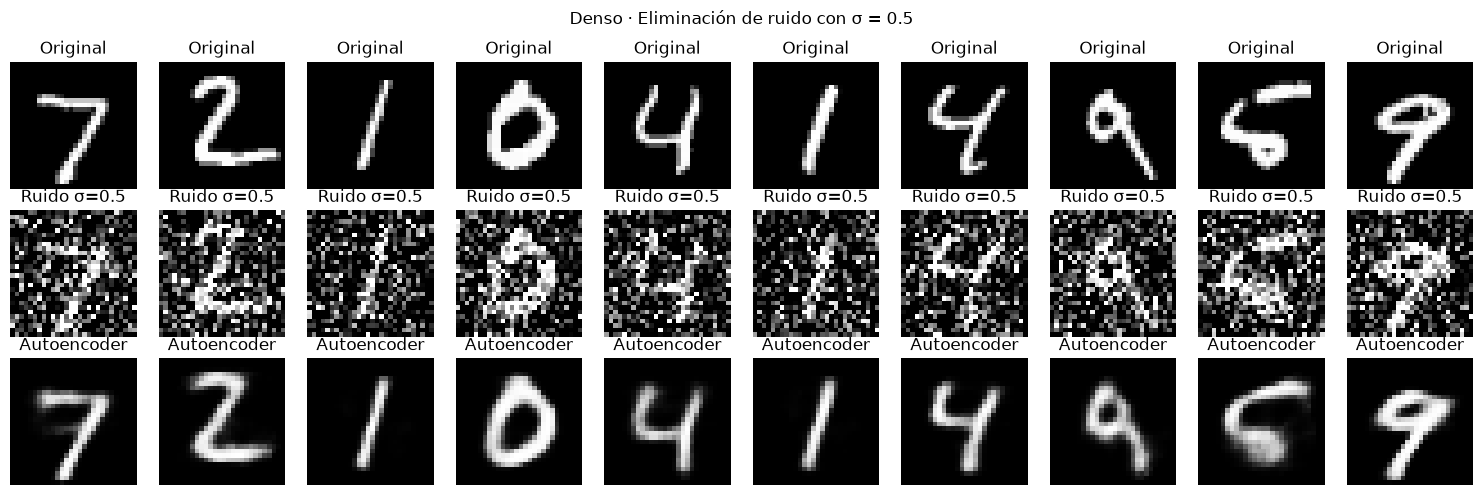

In [9]:
sigma = 0.5
resultados = {}

print("===== Autoencoder denso =====")
torch.manual_seed(42)  # misma inicialización que el convolucional
modelo_denso = AutoencoderDenso().to(device)
entrenar(modelo_denso, sigma)

resultados["Denso"] = evaluar(modelo_denso, sigma)
print(f"Test denso: MSE con ruido = {resultados['Denso'][0]:.4f} | MSE reconstruida = {resultados['Denso'][1]:.4f}")

visualizar_ruido(modelo_denso, sigma, nombre="Denso")

===== Autoencoder convolucional =====


σ=0.5 | Epoch 1/10 | Loss (MSE): 0.0368


σ=0.5 | Epoch 2/10 | Loss (MSE): 0.0156


σ=0.5 | Epoch 3/10 | Loss (MSE): 0.0134


σ=0.5 | Epoch 4/10 | Loss (MSE): 0.0125


σ=0.5 | Epoch 5/10 | Loss (MSE): 0.0120


... (2 outputs left out)

σ=0.5 | Epoch 8/10 | Loss (MSE): 0.0112


σ=0.5 | Epoch 9/10 | Loss (MSE): 0.0111


σ=0.5 | Epoch 10/10 | Loss (MSE): 0.0110


Test convolucional: MSE con ruido = 0.1156 | MSE reconstruida = 0.0109


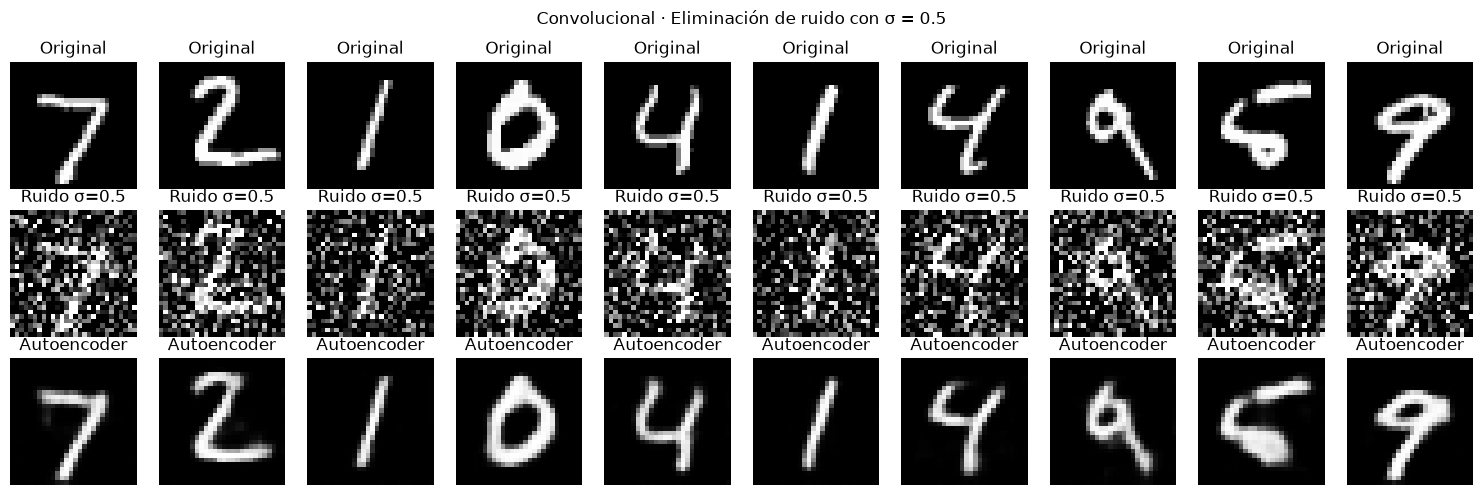

In [10]:
print("===== Autoencoder convolucional =====")
torch.manual_seed(42)  # misma inicialización que el denso
modelo_cnn = AutoencoderCNN().to(device)
entrenar(modelo_cnn, sigma)

resultados["Convolucional"] = evaluar(modelo_cnn, sigma)
print(f"Test convolucional: MSE con ruido = {resultados['Convolucional'][0]:.4f} | MSE reconstruida = {resultados['Convolucional'][1]:.4f}")

visualizar_ruido(modelo_cnn, sigma, nombre="Convolucional")

## Comparación

In [11]:
# El MSE con ruido es el mismo para los dos (mismo ruido de test gracias a la semilla de evaluar)
print(f"{'Modelo':>14} | {'MSE con ruido':>14} | {'MSE autoencoder':>16}")
print("-" * 50)
for nombre, (mse_ruido, mse_recon) in resultados.items():
    print(f"{nombre:>14} | {mse_ruido:>14.4f} | {mse_recon:>16.4f}")

mejor = min(resultados, key=lambda nombre: resultados[nombre][1])
print(f"\nMejor modelo: {mejor}")

        Modelo |  MSE con ruido |  MSE autoencoder
--------------------------------------------------
         Denso |         0.1156 |           0.0160
 Convolucional |         0.1156 |           0.0109

Mejor modelo: Convolucional


## Conclusiones

| Modelo | MSE con ruido | MSE autoencoder |
|---|---|---|
| Denso | 0.1156 | 0.0160 |
| Convolucional | 0.1156 | **0.0109** |

- Los dos autoencoders limpian bien el ruido: el error baja de 0.1156 (imagen con ruido) a 0.0160 con el denso (unas 7 veces menos) y a 0.0109 con el convolucional (más de 10 veces menos).
- **El convolucional es el mejor:** tiene un 32 % menos de error que el denso, a pesar de tener menos de la mitad de parámetros (unos 212 000 frente a 485 000). Las convoluciones aprovechan que los píxeles vecinos están relacionados, mientras que el denso aplana la imagen y pierde esa estructura espacial.
- En las figuras se nota la diferencia: el convolucional da trazos más nítidos y uniformes, mientras que el denso sale más borroso y algunos dígitos finos (los 1) quedan más tenues.
- Por eso usamos el **autoencoder convolucional** en el resto de la práctica (02, 03 y 04).